# Data Preprocessing & Feature Engineering

**Project:** Bank Marketing Campaign Analysis  
**Objective:** Prepare data for machine learning models

---

## 1. Setup

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

## 2. Load Data

In [2]:
# Load dataset
df = pd.read_csv("../data/raw/train.csv")

print(f"Shape: {df.shape}")
df.head()

Shape: (22605, 18)


,SampleId,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,57,unemployed,married,secondary,no,2299,no,no,cellular,12,nov,39,3,-1,0,unknown,False
1,1,31,services,married,secondary,no,246,yes,no,unknown,16,may,230,2,-1,0,unknown,False
2,2,58,retired,married,secondary,no,1230,no,no,cellular,20,may,420,1,87,1,failure,True
3,3,32,technician,single,tertiary,no,569,no,yes,cellular,29,jan,348,1,-1,0,unknown,False
4,4,54,entrepreneur,married,secondary,no,0,no,yes,cellular,15,jul,209,4,-1,0,unknown,False


In [3]:
# Basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22605 entries, 0 to 22604
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   SampleId   22605 non-null  int64 
 1   age        22605 non-null  int64 
 2   job        22605 non-null  object
 3   marital    22605 non-null  object
 4   education  22605 non-null  object
 5   default    22605 non-null  object
 6   balance    22605 non-null  int64 
 7   housing    22605 non-null  object
 8   loan       22605 non-null  object
 9   contact    22605 non-null  object
 10  day        22605 non-null  int64 
 11  month      22605 non-null  object
 12  duration   22605 non-null  int64 
 13  campaign   22605 non-null  int64 
 14  pdays      22605 non-null  int64 
 15  previous   22605 non-null  int64 
 16  poutcome   22605 non-null  object
 17  y          22605 non-null  bool  
dtypes: bool(1), int64(8), object(9)
memory usage: 3.0+ MB


## 3. Data Quality Check

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")

Missing Values:
SampleId     0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total missing: 0


In [5]:
# Check duplicates
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [6]:
# Check for 'unknown' values in categorical columns
categorical_cols = df.select_dtypes(include='object').columns

print("Unknown values in categorical features:")
for col in categorical_cols:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"{col:15s}: {unknown_count:5d} ({unknown_count/len(df)*100:.2f}%)")

Unknown values in categorical features:
job            :   141 (0.62%)
education      :   955 (4.22%)
contact        :  6423 (28.41%)
poutcome       : 18472 (81.72%)


## 4. Feature Selection

In [7]:
# Drop low-value features based on EDA
# SampleId: Identifier | previous, default, loan: Low predictive value
df.drop(columns=['SampleId', 'previous', 'default', 'loan'], inplace=True)

print(f"Shape after feature selection: {df.shape}")

Shape after feature selection: (22605, 14)


## 5. Handle Missing & Unknown Values

In [8]:
# Remove rows with unknown job
#before = len(df)
#df = df[df['job'] != 'unknown']
#print(f"Removed {before - len(df)} rows with unknown job")

In [9]:
# Remove rows with unknown education
#before = len(df)
#df = df[df['education'] != 'unknown']
#print(f"Removed {before - len(df)} rows with unknown education")
#print(f"\nFinal shape: {df.shape}")

## 6. Outlier Treatment

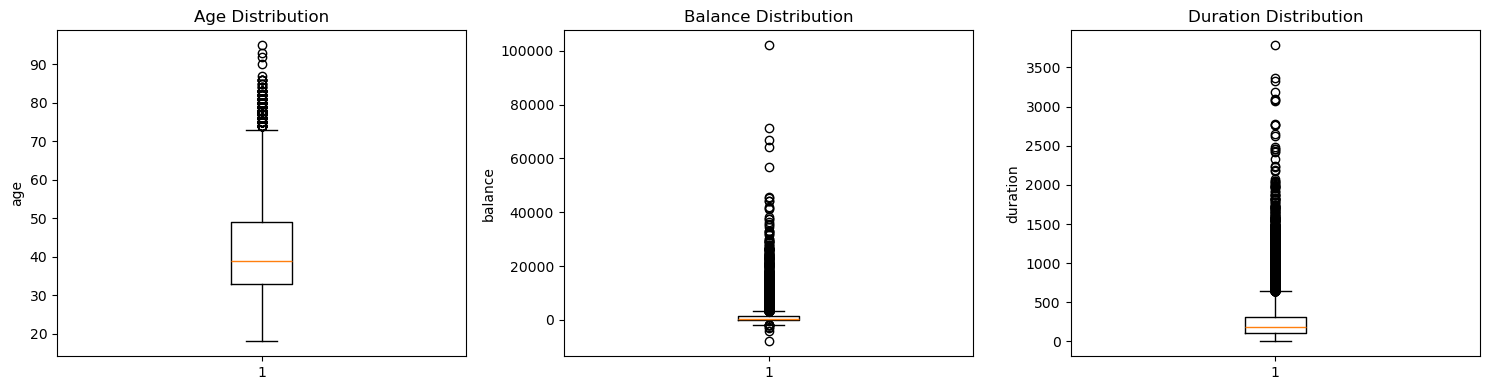

In [10]:
# Visualize outliers in key numerical features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, col in enumerate(['age', 'balance', 'duration']):
    axes[idx].boxplot(df[col])
    axes[idx].set_title(f'{col.capitalize()} Distribution')
    axes[idx].set_ylabel(col)

plt.tight_layout()
plt.show()

In [11]:
# Check outliers statistics
print("Outlier Analysis:")
for col in ['age', 'balance', 'duration', 'campaign']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    print(f"{col:10s}: {outliers:5d} outliers ({outliers/len(df)*100:.2f}%)")

Outlier Analysis:
age       :   172 outliers (0.76%)
balance   :  2392 outliers (10.58%)
duration  :  1652 outliers (7.31%)
campaign  :  1553 outliers (6.87%)


## 7. Feature Engineering

### 7.1 Age Binning

In [12]:
# Convert age to categorical bins
df['age'] = pd.cut(df['age'], 
                   bins=[17, 29, 45, 60, 95], 
                   labels=['young', 'adult', 'middle_aged', 'senior'])

print("Age distribution:")
print(df['age'].value_counts().sort_index())

Age distribution:
age
young           2680
adult          12671
middle_aged     6656
senior           598
Name: count, dtype: int64


### 7.2 Balance Transformation

In [13]:
# Log transformation to reduce skewness
balance_min = df['balance'].min()
df['balance'] = np.log1p(df['balance'] - balance_min)

print(f"Balance range after transformation: [{df['balance'].min():.2f}, {df['balance'].max():.2f}]")

Balance range after transformation: [0.00, 11.61]


### 7.3 Duration Transformation

In [14]:
# Log transformation for call duration
df['duration'] = np.log1p(df['duration'])

print(f"Duration range after transformation: [{df['duration'].min():.2f}, {df['duration'].max():.2f}]")

Duration range after transformation: [0.00, 8.24]


### 7.4 Campaign Transformation

In [15]:
# Log transformation for number of contacts
df['campaign'] = np.log1p(df['campaign'])

print(f"Campaign range after transformation: [{df['campaign'].min():.2f}, {df['campaign'].max():.2f}]")

Campaign range after transformation: [0.69, 4.16]


### 7.5 Cyclical Month Encoding

In [16]:
# Convert month to cyclical features (sin/cos)
month_mapping = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
    'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}

df['month_num'] = df['month'].map(month_mapping)
df['month_sin'] = np.sin(2 * np.pi * df['month_num'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month_num'] / 12)

df.drop(columns=['month', 'month_num'], inplace=True)

print("Cyclical month features created: month_sin, month_cos")

Cyclical month features created: month_sin, month_cos


## 8. Target Variable

In [17]:
# Rename and prepare target variable
df.rename(columns={'y': 'subscribed'}, inplace=True)

print("Target distribution (before encoding):")
print(df['subscribed'].value_counts())

Target distribution (before encoding):
subscribed
False    19918
True      2687
Name: count, dtype: int64


## 9. Encoding Categorical Variables

### 9.1 One-Hot Encoding

In [18]:
# One-hot encode nominal categorical variables
df = pd.get_dummies(df, columns=['job', 'marital', 'contact', 'poutcome'], drop_first=True, dtype=int)

print(f"Shape after one-hot encoding: {df.shape}")

Shape after one-hot encoding: (22605, 29)


### 9.2 Ordinal Encoding

In [19]:
# Ordinal encode education (ordered categories)
df['education'] = df['education'].map({'unknown': 0, 'primary': 1, 'secondary': 2, 'tertiary': 3})

print("Education encoding: unknown=0, primary=1, secondary=2, tertiary=3")

Education encoding: unknown=0, primary=1, secondary=2, tertiary=3


### 9.3 Binary Encoding

In [20]:
# Binary encode housing
df['housing'] = df['housing'].replace({'yes': 1, 'no': 0})

# Binary encode target variable
df['subscribed'] = df['subscribed'].map({False: 0, True: 1})

print("Binary encoding completed for housing and subscribed")

Binary encoding completed for housing and subscribed


### 9.4 Age Dummy Variables

In [21]:
# Create dummy variables for age categories
age_dummies = pd.get_dummies(df['age'], prefix='age', drop_first=True, dtype=int)
df = pd.concat([df, age_dummies], axis=1)
df.drop(columns=['age'], inplace=True)

print(f"Age dummy columns created: {list(age_dummies.columns)}")

Age dummy columns created: ['age_adult', 'age_middle_aged', 'age_senior']


## 10. Final Dataset Overview

In [22]:
# Display final dataset shape and info
print(f"Final dataset shape: {df.shape}")
print(f"\nFeatures: {df.shape[1]}")
print(f"Samples: {df.shape[0]}")
print(f"\nMissing values: {df.isnull().sum().sum()}")

Final dataset shape: (22605, 31)

Features: 31
Samples: 22605

Missing values: 0


In [23]:
# List all features
print("All features:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}")

All features:
 1. education
 2. balance
 3. housing
 4. day
 5. duration
 6. campaign
 7. pdays
 8. subscribed
 9. month_sin
10. month_cos
11. job_blue-collar
12. job_entrepreneur
13. job_housemaid
14. job_management
15. job_retired
16. job_self-employed
17. job_services
18. job_student
19. job_technician
20. job_unemployed
21. job_unknown
22. marital_married
23. marital_single
24. contact_telephone
25. contact_unknown
26. poutcome_other
27. poutcome_success
28. poutcome_unknown
29. age_adult
30. age_middle_aged
31. age_senior


In [24]:
# Check data types
print("Data types:")
print(df.dtypes.value_counts())

Data types:
int64      26
float64     5
Name: count, dtype: int64


In [25]:
# Target variable distribution
print("Target distribution:")
print(df['subscribed'].value_counts())
print(f"\nClass balance: {df['subscribed'].value_counts(normalize=True) * 100}")

Target distribution:
subscribed
0    19918
1     2687
Name: count, dtype: int64

Class balance: subscribed
0    88.113249
1    11.886751
Name: proportion, dtype: float64


In [26]:
# Display first rows of preprocessed data
df.head(10)

,education,balance,housing,day,duration,campaign,pdays,subscribed,month_sin,month_cos,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,age_adult,age_middle_aged,age_senior
0,2,9.241742,0,12,3.688879,1.386294,-1,0,-5.000000e-01,0.866025,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0
1,2,9.019906,1,16,5.442418,1.098612,-1,0,5.000000e-01,-0.866025,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,1,0,0
2,2,9.132379,0,20,6.042633,0.693147,87,1,5.000000e-01,-0.866025,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,3,9.058238,0,29,5.855072,0.693147,-1,0,5.000000e-01,0.866025,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1,0,0
4,2,8.989694,0,15,5.347108,1.609438,-1,0,-5.000000e-01,-0.866025,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0
5,2,9.165657,1,22,5.700444,0.693147,10,1,5.000000e-01,-0.866025,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0
6,2,8.993055,1,29,5.068904,0.693147,-1,0,5.000000e-01,-0.866025,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,1,1,0,0
7,3,9.244549,0,27,4.867534,2.079442,-1,0,-8.660254e-01,-0.500000,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0
8,3,8.966867,1,8,4.852030,0.693147,170,0,5.000000e-01,-0.866025,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
9,2,9.022564,0,3,4.317488,1.098612,90,0,1.224647e-16,-1.000000,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0


In [27]:
# Statistical summary
df.describe()

,education,balance,housing,day,duration,campaign,pdays,subscribed,month_sin,month_cos,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,age_adult,age_middle_aged,age_senior
count,22605.000000,22605.000000,22605.00000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,2.260500e+04,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000
mean,2.057863,9.116979,0.55470,15.826322,5.172224,1.161017,40.384782,0.118868,1.691988e-02,-0.469690,0.215616,0.032382,0.027118,0.209113,0.050653,0.034594,0.094271,0.021765,0.165893,0.028003,0.006238,0.600442,0.287149,0.064587,0.284141,0.040655,0.033665,0.817164,0.560540,0.294448,0.026454
std,0.783510,0.215332,0.49701,8.310309,0.917945,0.514037,100.254652,0.323640,6.126263e-01,0.635475,0.411258,0.177017,0.162431,0.406684,0.219292,0.182753,0.292212,0.145919,0.371992,0.164984,0.078733,0.489818,0.452442,0.245802,0.451014,0.197493,0.180370,0.386540,0.496332,0.455804,0.160486
min,0.000000,0.000000,0.00000,1.000000,0.000000,0.693147,-1.000000,0.000000,-1.000000e+00,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,8.998755,0.00000,8.000000,4.644391,0.693147,-1.000000,0.000000,-5.000000e-01,-0.866025,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,2.000000,9.043459,1.00000,16.000000,5.192957,1.098612,-1.000000,0.000000,1.224647e-16,-0.866025,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
75%,3.000000,9.150697,1.00000,21.000000,5.765191,1.386294,-1.000000,0.000000,5.000000e-01,-0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
max,3.000000,11.609571,1.00000,31.000000,8.239065,4.158883,854.000000,1.000000,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 11. Save Preprocessed Data

In [28]:
# Save to CSV

output_path = "../data/processed/train_preprocessed.csv"
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df.to_csv(output_path, index=False)

print(f"✓ Preprocessed data saved to: {output_path}")
print(f"✓ Shape: {df.shape}")
print(f"✓ Ready for modeling!")

✓ Preprocessed data saved to: ../data/processed/train_preprocessed.csv
✓ Shape: (22605, 31)
✓ Ready for modeling!


---
## Preprocessing Summary

**Completed Steps:**
1. ✅ Data loading and quality check
2. ✅ Feature selection (removed low-value features)
3. ✅ Handled missing and unknown values
4. ✅ Outlier analysis
5. ✅ Feature engineering (binning, transformations)
6. ✅ Cyclical encoding for temporal features
7. ✅ Categorical encoding (one-hot, ordinal, binary)
8. ✅ Dataset saved for modeling

**Key Transformations:**
- Age → Categorical bins
- Balance, Duration, Campaign → Log transformation
- Month → Cyclical sin/cos features
- Job, Marital, Contact, poutcome → One-hot encoded
- Education → Ordinal encoded
- Housing, Target → Binary encoded